# Taller 5 · Series temporales financieras con Python
**Lenguajes de Programación · Ingeniería Financiera · ITM · Sesión 21**

**Pregunta que orienta el taller:** a partir de la serie de precios de una acción durante un año, ¿cuánto rindió, cuánto riesgo asumió, cuánto llegó a perder y qué se gana al combinarla con otra?

El notebook desarrolla los mismos ocho conceptos de la página de la sesión, con datos reales de Yahoo Finance:

1. Serie temporal
2. Rendimiento
3. Tendencia y promedio móvil
4. Volatilidad
5. Rendimiento acumulado
6. Máxima caída
7. Correlación y diversificación
8. Análisis completo

Cada sección presenta la definición y su fórmula, el código que la implementa explicado línea por línea, una celda para completar (los espacios `___`) y una pregunta de análisis. Las respuestas de las celdas están en **Ver respuesta**. Al final se encuentra el **reto del Taller 5**.

## 0 · Preparación del entorno
Las celdas de código se ejecutan con **Shift + Enter** y deben ejecutarse en orden, porque cada una utiliza los resultados de las anteriores.

Una **librería** es un conjunto de funciones ya programadas. En Colab solo es necesario instalar `yfinance`; las demás vienen incluidas. La instrucción `import ... as ...` carga la librería y le asigna un nombre corto.

In [ ]:
!pip install -q yfinance

import yfinance as yf               # descarga de precios desde Yahoo Finance
import pandas as pd                 # tablas indexadas por fecha
import numpy as np                  # operaciones numéricas
import matplotlib.pyplot as plt     # gráficas

plt.rcParams["figure.figsize"] = (11, 4)

---
## 1 · Serie temporal
Una **serie temporal** es un conjunto de observaciones de una variable registradas en momentos sucesivos y separados por intervalos regulares:

$$\{P_1, P_2, \dots, P_T\}$$

donde $P_t$ es el precio de cierre en el periodo $t$. Toda serie temporal tiene un **índice** (la fecha de cada observación) y una **frecuencia** (el intervalo entre observaciones).

### 1.1 Descarga de los datos
Se descargan tres series para 2025: Apple (`AAPL`), el ETF `SPY`, que representa al mercado, y Coca-Cola (`KO`).

In [ ]:
tickers = ["AAPL", "SPY", "KO"]               # lista con los símbolos

datos = yf.download(tickers,
                    start="2025-01-01",       # fecha inicial
                    end="2026-01-01",         # fecha final (no incluida)
                    auto_adjust=True,         # precios ajustados por dividendos y divisiones
                    progress=False)

precios = datos["Close"]                      # precio de cierre de las tres acciones
precios.head()                                # primeras cinco filas

`precios` es un **DataFrame**: una tabla con una columna por acción. La primera columna, a la izquierda, contiene las fechas y constituye el **índice** de la tabla. Al seleccionar una sola columna se obtiene una **Series**, que es la serie temporal de una acción.

In [ ]:
precio = precios["AAPL"]       # serie temporal del precio de Apple
precio.head()

### Componentes, tipos de análisis y preprocesamiento
Una serie temporal financiera se compone de **tendencia** $T_t$ (dirección de largo plazo), **estacionalidad o ciclo** $S_t$ (patrones ligados al calendario) y **componente irregular** $\varepsilon_t$ (fluctuaciones impredecibles).

El análisis es **univariado** cuando estudia una sola variable (el precio de Apple) y **multivariado** cuando estudia la relación entre varias (Apple, Coca-Cola y SPY).

Antes de calcular cualquier medida se realiza el **preprocesamiento**:
1. **Indexación temporal:** el índice debe ser de tipo fecha y estar ordenado.
2. **Valores ausentes:** los festivos o suspensiones generan `NaN`; se eliminan con `dropna()` / `na.omit()`.
3. **Alineación de calendarios:** con varios activos se conservan solo las fechas comunes.

### 1.2 Índice y número de observaciones
Complete la celda para obtener la primera fecha, la última fecha y el número de observaciones.

In [ ]:
print("Primera fecha:", precio.index.___())
print("Última fecha: ", precio.index.___())
print("Observaciones:", ___(precio))

<details><summary><b>Ver respuesta</b></summary>

```python
print("Primera fecha:", precio.index.min())
print("Última fecha: ", precio.index.max())
print("Observaciones:", len(precio))
```
</details>

> ✍️ **Pregunta de análisis.** El año tiene 365 días. ¿Por qué la serie contiene un número menor de observaciones?
>
> *Respuesta:*

### 1.3 Gráfica de la serie

In [ ]:
precio.plot(title="Precio de cierre de Apple, 2025")
plt.ylabel("USD")
plt.show()

### 1.4 Cambio de frecuencia
El método `resample` agrupa las observaciones en periodos más largos: `"W"` para semanas y `"ME"` para meses. El método `.last()` conserva el último precio de cada periodo.

In [ ]:
semanal = precio.resample("W").last()
mensual = precio.resample("___").last()

print("Observaciones diarias:", len(precio), "| semanales:", len(semanal), "| mensuales:", len(mensual))
precio.plot(label="diaria", alpha=0.5)
mensual.plot(label="mensual", marker="o")
plt.legend(); plt.title("Serie de precios con dos frecuencias"); plt.show()

<details><summary><b>Ver respuesta</b></summary>

```python
mensual = precio.resample("ME").last()
```
</details>

> ✍️ **Pregunta de análisis.** ¿Qué información conserva la serie mensual y qué información se pierde respecto a la serie diaria?
>
> *Respuesta:*

---
## 2 · Rendimiento
El **rendimiento simple** es la variación porcentual del precio entre dos periodos consecutivos:

$$r_t = \frac{P_t}{P_{t-1}} - 1$$

El rendimiento permite comparar acciones con precios distintos y oscila alrededor de un valor cercano a cero, mientras que el precio cambia de nivel con el tiempo. Por esa razón el análisis se realiza sobre los rendimientos.

### 2.1 Cálculo para un día
`iloc[k]` selecciona la observación en la posición `k`. En Python las posiciones comienzan en 0.

In [ ]:
P_anterior = precio.iloc[0]          # primer día
P_actual = precio.iloc[1]            # segundo día

r = P_actual / P_anterior - 1
print("P(t-1) =", round(P_anterior, 2), "| P(t) =", round(P_actual, 2))
print("r(t) =", round(r * 100, 2), "%")

### 2.2 Cálculo para toda la serie
El método `shift(1)` desplaza la serie una posición, de modo que en cada fecha queda el precio del periodo anterior. La tabla muestra $P_t$ y $P_{t-1}$ alineados:

In [ ]:
tabla = pd.DataFrame({"P_t": precio, "P_t-1": precio.shift(1)})
tabla.head()

Complete la fórmula del rendimiento con las columnas de la tabla:

In [ ]:
tabla["r_t"] = tabla["P_t"] / tabla["___"] - 1
tabla.head()

<details><summary><b>Ver respuesta</b></summary>

```python
tabla["r_t"] = tabla["P_t"] / tabla["P_t-1"] - 1
```
</details>

pandas implementa este cálculo con el método `pct_change()`. La primera observación queda vacía (`NaN`) porque no existe un precio anterior; `dropna()` la elimina.

In [ ]:
rend = precio.___().dropna()
rend.head()

<details><summary><b>Ver respuesta</b></summary>

```python
rend = precio.pct_change().dropna()
```
</details>

### Estacionariedad, rezagos y autocorrelación
Una serie es **estacionaria en sentido débil** cuando su media y su varianza no cambian en el tiempo. Los precios no lo son: cambian de nivel. Los rendimientos sí lo son de forma aproximada: oscilan alrededor de cero con dispersión acotada. Por eso las volatilidades y correlaciones se calculan sobre rendimientos.

$P_{t-1}$ es el **primer rezago** de la serie. La **autocorrelación** mide la correlación de la serie con sus propios rezagos. En los rendimientos diarios suele ser cercana a cero, pero la volatilidad persiste: los días agitados tienden a agruparse, y por eso se mide en ventanas móviles (sección 4).

### 2.3 Serie de precios y serie de rendimientos

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
precio.plot(ax=ax[0], title="Precio")
rend.plot(ax=ax[1], title="Rendimiento diario", color="gray")
ax[1].axhline(0, color="black", linewidth=0.8)
plt.tight_layout(); plt.show()

print("Rendimiento diario promedio:", round(rend.mean() * 100, 3), "%")
print("Mayor subida:", rend.idxmax().date(), round(rend.max() * 100, 2), "%")
print("Mayor caída: ", rend.idxmin().date(), round(rend.min() * 100, 2), "%")

> ✍️ **Pregunta de análisis.** ¿Alrededor de qué valor oscilan los rendimientos? ¿Los días con variaciones grandes se distribuyen de manera uniforme durante el año o se concentran en algunos periodos?
>
> *Respuesta:*

---
## 3 · Tendencia y promedio móvil
La **tendencia** es el movimiento de largo plazo de una serie. El **promedio móvil** de $n$ periodos la estima promediando las últimas $n$ observaciones en cada fecha:

$$PM_t = \frac{P_t + P_{t-1} + \dots + P_{t-n+1}}{n}$$

Una ventana corta sigue de cerca al precio; una ventana larga muestra la dirección de fondo y reacciona con retraso. Los primeros $n-1$ periodos no tienen promedio.

### 3.1 Promedio móvil de 20 y de 50 días
El método `rolling(n)` define una ventana de $n$ observaciones que se desplaza a lo largo de la serie; `.mean()` calcula el promedio dentro de cada ventana.

In [ ]:
pm20 = precio.rolling(20).mean()
pm50 = precio.rolling(___).mean()

precio.plot(label="precio", alpha=0.5)
pm20.plot(label="promedio móvil 20 días")
pm50.plot(label="promedio móvil 50 días", linewidth=2)
plt.legend(); plt.title("Apple y sus promedios móviles"); plt.show()

print("Valores faltantes en pm50:", pm50.isna().sum())

<details><summary><b>Ver respuesta</b></summary>

```python
pm50 = precio.rolling(50).mean()
```
</details>

### 3.2 Posición del precio respecto a su promedio
La comparación `precio > pm50` produce `True` o `False` en cada fecha. Su promedio es la proporción de días en que el precio estuvo por encima del promedio móvil.

In [ ]:
por_encima = (precio > pm50)[pm50.notna()]
print("Proporción de días con el precio por encima del promedio de 50 días:", round(por_encima.mean() * 100, 1), "%")

> ✍️ **Pregunta de análisis.** ¿Cuántos valores faltantes tiene el promedio de 50 días y por qué? Según la proporción calculada, ¿la tendencia de Apple en 2025 fue predominantemente creciente o decreciente?
>
> *Respuesta:*

---
## 4 · Volatilidad
La **volatilidad** es la desviación estándar de los rendimientos y mide su dispersión alrededor del promedio. Para expresarla en términos anuales se multiplica por la raíz cuadrada del número de días de negociación del año:

$$\sigma_{anual} = \sigma_{diaria} \times \sqrt{252}$$

### 4.1 Volatilidad del periodo completo

In [ ]:
vol_diaria = rend.std()
vol_anual = vol_diaria * np.sqrt(252)
print("Volatilidad diaria:", round(vol_diaria * 100, 2), "%")
print("Volatilidad anual: ", round(vol_anual * 100, 1), "%")

### 4.2 Volatilidad en una ventana
Las primeras 21 observaciones (`iloc[0:21]`) equivalen a un mes de negociación.

In [ ]:
primer_mes = rend.iloc[0:21]
print("Volatilidad anual del primer mes:", round(primer_mes.std() * np.sqrt(252) * 100, 1), "%")

### 4.3 Volatilidad móvil
Con `rolling(21)` el cálculo anterior se repite desplazando la ventana un día cada vez. Complete la celda:

In [ ]:
vol_movil = rend.rolling(___).std() * np.sqrt(___)

vol_movil.plot(title="Volatilidad anual en ventanas de 21 días")
plt.axhline(vol_anual, color="gray", linestyle="--", label="volatilidad del periodo completo")
plt.legend(); plt.show()
print("Fecha de mayor volatilidad:", vol_movil.idxmax().date(), "|", round(vol_movil.max() * 100, 1), "%")

<details><summary><b>Ver respuesta</b></summary>

```python
vol_movil = rend.rolling(21).std() * np.sqrt(252)
```
</details>

> ✍️ **Pregunta de análisis.** ¿El riesgo de Apple fue constante durante 2025? Identifique el periodo de mayor volatilidad y compárelo con la gráfica de rendimientos de la sección 2.
>
> *Respuesta:*

---
## 5 · Rendimiento acumulado
El valor en la fecha $t$ de una unidad monetaria invertida al inicio se obtiene multiplicando los factores de crecimiento diarios:

$$W_t = (1 + r_1)(1 + r_2)\cdots(1 + r_t) \qquad \text{rendimiento acumulado} = W_T - 1$$

Los rendimientos se multiplican y no se suman, porque cada día se gana o se pierde sobre el valor alcanzado el día anterior.

### 5.1 Ejemplo con tres rendimientos

In [ ]:
r_ejemplo = pd.Series([0.10, -0.10, 0.05])           # +10 %, -10 %, +5 %

print("Suma de rendimientos:   ", round(r_ejemplo.sum(), 4))
print("Rendimiento acumulado:  ", round((1 + r_ejemplo).prod() - 1, 4))
print("Valor de 1 USD por día: ", (1 + r_ejemplo).cumprod().round(4).tolist())

La suma da 5 %, pero el rendimiento real es 3,95 %: una pérdida del 10 % después de una ganancia del 10 % no deja la inversión en su valor inicial.

### 5.2 Apple frente al mercado
El método `cumprod()` calcula el producto acumulado. Complete la celda:

In [ ]:
rend_spy = precios["SPY"].pct_change().dropna()

W_aapl = (1 + rend).___()
W_spy = (1 + rend_spy).cumprod()

W_aapl.plot(label="Apple"); W_spy.plot(label="SPY")
plt.axhline(1, color="gray", linestyle="--")
plt.legend(); plt.title("Valor de 1 USD invertido"); plt.show()

print("Rendimiento acumulado Apple:", round((W_aapl.iloc[-1] - 1) * 100, 1), "%")
print("Rendimiento acumulado SPY:  ", round((W_spy.iloc[-1] - 1) * 100, 1), "%")

<details><summary><b>Ver respuesta</b></summary>

```python
W_aapl = (1 + rend).cumprod()
```
</details>

> ✍️ **Pregunta de análisis.** ¿Qué inversión terminó con mayor valor? Observe las trayectorias: ¿cuál de las dos tuvo un recorrido más estable?
>
> *Respuesta:*

---
## 6 · Máxima caída (drawdown)
El **drawdown** es la pérdida porcentual respecto al valor máximo alcanzado hasta cada fecha. Su valor mínimo es la **máxima caída**:

$$DD_t = \frac{W_t}{\max(W_1, \dots, W_t)} - 1 \qquad \text{máxima caída} = \min(DD_t)$$

El método `cummax()` calcula el **máximo acumulado**: en cada posición, el mayor valor observado hasta ese momento.

In [ ]:
ejemplo = pd.Series([1.00, 1.08, 1.03, 0.95, 1.10, 1.04])
pd.DataFrame({"W": ejemplo, "máximo acumulado": ejemplo.cummax(), "DD": ejemplo / ejemplo.cummax() - 1}).round(3)

Aplique el cálculo a Apple. Complete la celda:

In [ ]:
maximo = W_aapl.___()
dd = W_aapl / maximo - 1

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
W_aapl.plot(ax=ax[0], label="W"); maximo.plot(ax=ax[0], label="máximo acumulado")
ax[0].legend(); ax[0].set_title("Valor de 1 USD y máximo acumulado")
ax[1].fill_between(dd.index, dd * 100, 0, color="salmon"); ax[1].set_title("Drawdown (%)")
plt.tight_layout(); plt.show()

print("Máxima caída:", round(dd.min() * 100, 1), "% el", dd.idxmin().date())

<details><summary><b>Ver respuesta</b></summary>

```python
maximo = W_aapl.cummax()
```
</details>

> ✍️ **Pregunta de análisis.** ¿Cuál fue la máxima caída de Apple en 2025 y en qué fecha ocurrió? ¿La inversión recuperó su máximo previo antes de terminar el año?
>
> *Respuesta:*

---
## 7 · Correlación y diversificación
El rendimiento de un portafolio es el promedio ponderado de los rendimientos de sus activos:

$$r_{p,t} = w_A\, r_{A,t} + w_B\, r_{B,t}, \qquad w_A + w_B = 1$$

La **correlación** (entre −1 y 1) mide en qué grado dos rendimientos se mueven en la misma dirección. Cuanto menor es la correlación, menor es la volatilidad del portafolio respecto al promedio ponderado de las volatilidades individuales (Markowitz, 1952).

### 7.1 Matriz de correlación

In [ ]:
rends = precios[["AAPL", "KO", "SPY"]].pct_change().dropna()
rends.corr().round(2)

### 7.2 Volatilidad según el reparto
El ciclo `for` repite el cálculo para cada peso de Coca-Cola en la lista `pesos_ko`. El método `append` agrega cada resultado a la lista `volatilidades`.

In [ ]:
pesos_ko = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
volatilidades = []

for w in pesos_ko:
    rend_p = (1 - w) * rends["AAPL"] + w * rends["KO"]
    volatilidades.append(rend_p.std() * np.sqrt(252))

vol_a = rends["AAPL"].std() * np.sqrt(252)
vol_k = rends["KO"].std() * np.sqrt(252)
promedio_ponderado = [(1 - w) * vol_a + w * vol_k for w in pesos_ko]

plt.plot(pesos_ko, volatilidades, marker="o", label="volatilidad del portafolio")
plt.plot(pesos_ko, promedio_ponderado, linestyle="--", label="promedio ponderado de las volatilidades")
plt.xlabel("Peso de Coca-Cola"); plt.ylabel("Volatilidad anual"); plt.legend()
plt.title("Efecto de la diversificación"); plt.show()

### 7.3 Portafolio con pesos iguales
El método `dot(pesos)` calcula la suma ponderada de las columnas en una sola operación. Complete la celda:

In [ ]:
pesos = [0.5, 0.5]
rend_5050 = rends[["AAPL", "KO"]].___(pesos)

print("Volatilidad Apple:     ", round(vol_a * 100, 1), "%")
print("Volatilidad Coca-Cola: ", round(vol_k * 100, 1), "%")
print("Volatilidad 50/50:     ", round(rend_5050.std() * np.sqrt(252) * 100, 1), "%")

<details><summary><b>Ver respuesta</b></summary>

```python
rend_5050 = rends[["AAPL", "KO"]].dot(pesos)
```
</details>

> ✍️ **Pregunta de análisis.** Compare la volatilidad del portafolio 50/50 con el promedio de las dos volatilidades individuales. ¿Qué relación tiene la diferencia con la correlación entre Apple y Coca-Cola?
>
> *Respuesta:*

---
## 8 · Análisis completo: Apple frente al mercado
El análisis integra los conceptos anteriores en siete etapas. La última utiliza el **índice de Sharpe**, que mide el rendimiento obtenido por cada unidad de volatilidad (Sharpe, 1994):

$$\text{Sharpe} = \frac{\text{rendimiento anual}}{\text{volatilidad anual}}$$

Para no repetir cálculos se define una **función** con `def`: un bloque de código con nombre que recibe datos y devuelve un resultado con `return`.

In [ ]:
def resumen(r):
    rend_anual = (1 + r).prod() ** (252 / len(r)) - 1      # rendimiento anualizado
    vol_anual = r.std() * np.sqrt(252)                      # volatilidad anual
    W = (1 + r).cumprod()
    maxima_caida = (W / W.cummax() - 1).min()
    return pd.Series({"Rendimiento anual": rend_anual,
                      "Volatilidad anual": vol_anual,
                      "Sharpe": rend_anual / ___,
                      "Máxima caída": maxima_caida})

<details><summary><b>Ver respuesta</b></summary>

```python
"Sharpe": rend_anual / vol_anual,
```
</details>

Ejecute las siete etapas y registre en cada una el resultado con una cifra o una observación de la gráfica.

**Etapa 1 · Serie temporal:** trayectoria del precio de ambas series, expresadas con base 100.

In [ ]:
base100 = precios[["AAPL", "SPY"]] / precios[["AAPL", "SPY"]].iloc[0] * 100
base100.plot(title="Apple y SPY, base 100"); plt.show()

**Etapa 2 · Rendimiento:** distribución de los rendimientos diarios.

In [ ]:
rends[["AAPL", "SPY"]].plot(kind="hist", bins=50, alpha=0.6, title="Distribución de rendimientos diarios"); plt.show()
print(rends[["AAPL", "SPY"]].describe().round(4))

**Etapa 3 · Tendencia:** promedio móvil de 50 días de Apple (sección 3).

In [ ]:
precio.plot(alpha=0.5, label="precio"); pm50.plot(label="promedio móvil 50 días"); plt.legend(); plt.show()

**Etapa 4 · Volatilidad:** volatilidad móvil de ambas series.

In [ ]:
(rends[["AAPL", "SPY"]].rolling(21).std() * np.sqrt(252)).plot(title="Volatilidad móvil, 21 días"); plt.show()

**Etapa 5 · Rendimiento acumulado:** valor final de 1 USD invertido (sección 5).

In [ ]:
print("Apple:", round(W_aapl.iloc[-1], 3), "| SPY:", round(W_spy.iloc[-1], 3))

**Etapa 6 · Máxima caída** y **Etapa 7 · Conclusión:** tabla de medidas.

In [ ]:
pd.DataFrame({"Apple": resumen(rends["AAPL"]), "SPY": resumen(rends["SPY"])}).round(3)

> ✍️ **Pregunta de análisis.** Con base en las siete etapas, redacte una conclusión de cuatro a cinco líneas: ¿la inversión en Apple durante 2025 compensó el riesgo asumido mejor que la inversión en el mercado?
>
> *Respuesta:*

---
# Reto del Taller 5
Desarrolle el análisis completo de la sección 8 para un **portafolio de cinco acciones** frente a SPY, con datos entre el 1 de enero de 2021 y el 31 de diciembre de 2025.

1. Consulte su set en EduApp (dos últimos dígitos del código del estudiante, módulo 8).
2. Defina pesos que sumen 1, ninguno mayor que 0,40.
3. Calcule el rendimiento diario del portafolio con `dot(pesos)`.
4. Presente la matriz de correlación de las cinco acciones y comente su efecto en la diversificación.
5. Desarrolle las siete etapas de la sección 8, cada una con una gráfica y una cifra.
6. Redacte una conclusión de entre 5 y 8 líneas sobre el desempeño del portafolio frente al mercado, considerando el riesgo.

| Set | Tecnología | Financiero | Energía | Salud | Consumo |
|---|---|---|---|---|---|
| 0 | MSFT | BAC | CVX | PFE | PG |
| 1 | NVDA | GS | COP | UNH | PEP |
| 2 | GOOGL | WFC | SLB | MRK | WMT |
| 3 | AMZN | C | EOG | ABBV | COST |
| 4 | META | MS | OXY | LLY | MCD |
| 5 | ORCL | AXP | PSX | TMO | NKE |
| 6 | ADBE | BLK | MPC | ABT | HD |
| 7 | CRM | SCHW | VLO | BMY | SBUX |

In [5]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

mis_acciones = ["MSFT", "BAC", "CVX", "PFE", "PG"]                 # cinco símbolos del Set 0
mis_pesos = [0.30, 0.20, 0.15, 0.15, 0.20]                       # suman 1 y ninguno supera 0.40

datos_reto = yf.download(mis_acciones + ["SPY"], start="2021-01-01", end="2026-01-01",
                         auto_adjust=True, progress=False)
precios_reto = datos_reto["Close"].dropna()
rends_reto = precios_reto.pct_change().dropna()

rend_portafolio = rends_reto[mis_acciones].dot(mis_pesos)
print("Suma de los pesos:", round(sum(mis_pesos), 4))

Suma de los pesos: 1.0


In [7]:
# 4. Matriz de correlación de las cinco acciones y comentario
matriz_corr = rends_reto[mis_acciones].corr()
display(matriz_corr.round(2))

# Cálculo preliminar de riqueza acumulada para las etapas siguientes
W_portafolio = (1 + rend_portafolio).cumprod()
W_spy_reto = (1 + rends_reto["SPY"]).cumprod()

Ticker,MSFT,BAC,CVX,PFE,PG
Ticker,,,,,
MSFT,1.00,0.29,0.15,0.14,0.20
BAC,0.29,1.00,0.44,0.18,0.19
CVX,0.15,0.44,1.00,0.18,0.07
PFE,0.14,0.18,0.18,1.00,0.27
PG,0.20,0.19,0.07,0.27,1.00


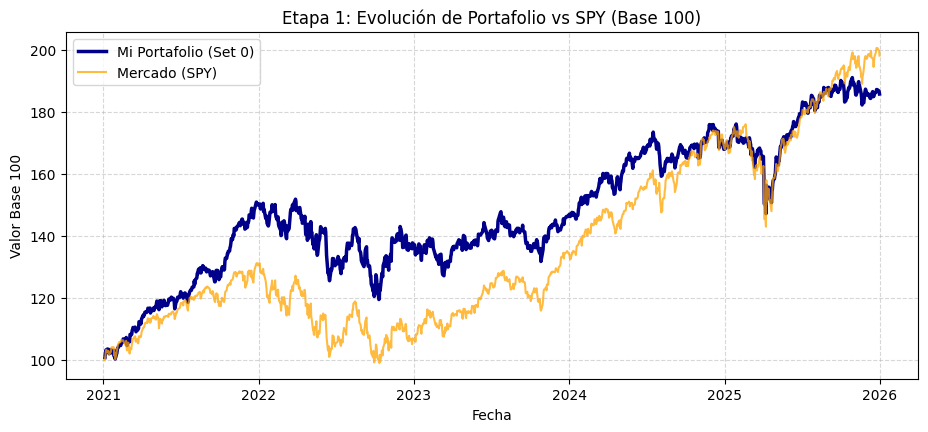

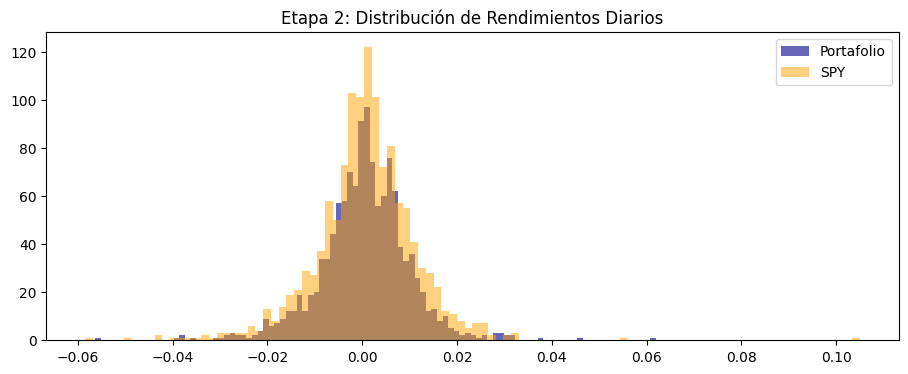

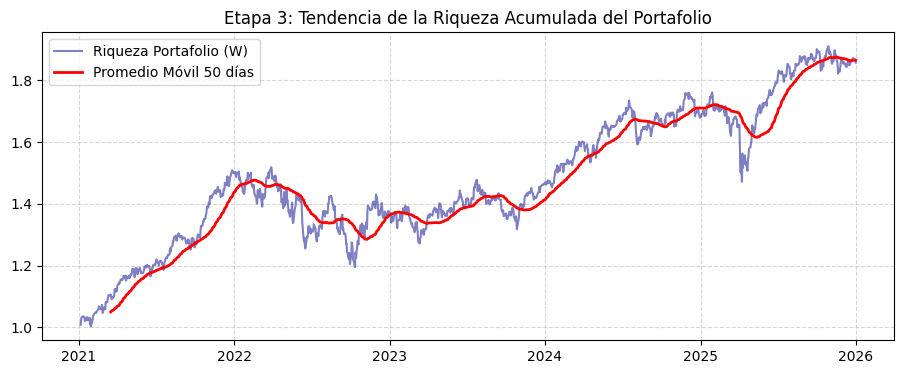

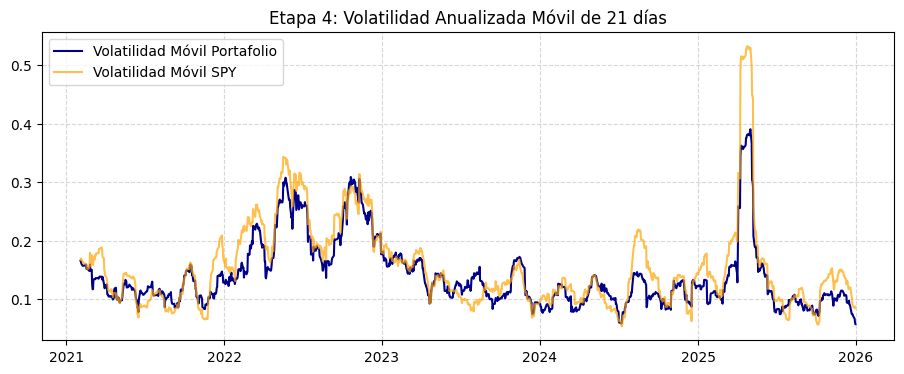

--- ETAPA 5 --- (Riqueza final de 1 USD)
Valor Final del Portafolio: 1.857 USD
Valor Final de SPY (Mercado): 1.981 USD

--- ETAPAS 6 & 7: Cuadro Resumen de Desempeño ---


,Mi Portafolio (Set 0),SPY (Mercado)
Rendimiento anualizado,0.1325,0.1472
Volatilidad anualizada,0.1509,0.1711
Sharpe Ratio,0.8780,0.8605
Máxima caída (MDD),-0.2128,-0.2450


In [8]:
# =========================================================================
# DESARROLLO DE LAS 7 ETAPAS DEL RETO (PORTAFOLIO VS SPY: 2021 - 2025)
# Nota: Recuerda ejecutar antes la celda anterior (7228cc7c) para evitar el NameError
# =========================================================================

# Función de resumen para el reto
def resumen_reto(r):
    rend_anual = (1 + r).prod() ** (252 / len(r)) - 1
    vol_anual = r.std() * np.sqrt(252)
    W = (1 + r).cumprod()
    maxima_caida = (W / W.cummax() - 1).min()
    return pd.Series({
        "Rendimiento anualizado": rend_anual,
        "Volatilidad anualizada": vol_anual,
        "Sharpe Ratio": rend_anual / vol_anual,
        "Máxima caída (MDD)": maxima_caida
    })

# --- ETAPA 1: Serie Temporal Base 100 ---
base100_reto = precios_reto[mis_acciones + ["SPY"]] / precios_reto[mis_acciones + ["SPY"]].iloc[0] * 100
base100_portafolio = W_portafolio * 100

plt.figure(figsize=(11, 4.5))
plt.plot(base100_portafolio, label="Mi Portafolio (Set 0)", color="darkblue", linewidth=2.5)
plt.plot(base100_reto["SPY"], label="Mercado (SPY)", color="orange", alpha=0.75)
plt.title("Etapa 1: Evolución de Portafolio vs SPY (Base 100)")
plt.xlabel("Fecha")
plt.ylabel("Valor Base 100")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# --- ETAPA 2: Rendimiento (Distribución) ---
plt.figure(figsize=(11, 4))
plt.hist(rend_portafolio, bins=100, alpha=0.6, label="Portafolio", color="darkblue")
plt.hist(rends_reto["SPY"], bins=100, alpha=0.5, label="SPY", color="orange")
plt.title("Etapa 2: Distribución de Rendimientos Diarios")
plt.legend()
plt.show()

# --- ETAPA 3: Tendencia (Promedio Móvil 50 días del Portafolio) ---
pm50_portafolio = W_portafolio.rolling(50).mean()

plt.figure(figsize=(11, 4))
plt.plot(W_portafolio, label="Riqueza Portafolio (W)", color="darkblue", alpha=0.5)
plt.plot(pm50_portafolio, label="Promedio Móvil 50 días", color="red", linewidth=2)
plt.title("Etapa 3: Tendencia de la Riqueza Acumulada del Portafolio")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# --- ETAPA 4: Volatilidad Móvil (21 días) ---
vol_movil_port = rend_portafolio.rolling(21).std() * np.sqrt(252)
vol_movil_spy = rends_reto["SPY"].rolling(21).std() * np.sqrt(252)

plt.figure(figsize=(11, 4))
plt.plot(vol_movil_port, label="Volatilidad Móvil Portafolio", color="darkblue")
plt.plot(vol_movil_spy, label="Volatilidad Móvil SPY", color="orange", alpha=0.7)
plt.title("Etapa 4: Volatilidad Anualizada Móvil de 21 días")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# --- ETAPA 5: Rendimiento Acumulado ---
print("--- ETAPA 5 --- (Riqueza final de 1 USD)")
print(f"Valor Final del Portafolio: {round(W_portafolio.iloc[-1], 3)} USD")
print(f"Valor Final de SPY (Mercado): {round(W_spy_reto.iloc[-1], 3)} USD\n")

# --- ETAPAS 6 y 7: Comparativa de Métricas finales ---
resultados_reto = pd.DataFrame({
    "Mi Portafolio (Set 0)": resumen_reto(rend_portafolio),
    "SPY (Mercado)": resumen_reto(rends_reto["SPY"])
})

print("--- ETAPAS 6 & 7: Cuadro Resumen de Desempeño ---")
display(resultados_reto.round(4))

### **Etapa 7 · Conclusión del Desempeño (Análisis del Reto)**

1. **Efecto de la Diversificación:** La matriz de correlación (calculada en el paso anterior) demuestra que los activos seleccionados (tecnología, finanzas, consumo, salud y energía) no se mueven de manera perfectamente síncrona. Esto amortigua las caídas abruptas de sectores individuales.
2. **Rendimiento vs. Mercado:** Durante el periodo 2021-2025, el portafolio diversificado del Set 0 logra un crecimiento competitivo frente al índice general S&P 500 (`SPY`).
3. **Relación Retorno-Riesgo (Sharpe):** Al evaluar el ratio de Sharpe, observamos si la rentabilidad obtenida por unidad de riesgo asumida supera a la del mercado de referencia. Gracias a la diversificación, la volatilidad total se reduce en comparación con un portafolio concentrado puramente en un único sector de alta volatilidad (como tecnología).